# Canadian case NTGS1 / NTGS2: fidelity porting against GEOtop 3.0

The snow+soil column of WHETGEO-1D in the **fidelity** configuration is run **heat only** (`soilWaterMode = Fixed`, as GEOtop's `WaterBalance = 0`). It is compared with **GEOtop 3.0 without canopy, corrected** (`casi/Canada_NTGS/sims/<case>_senza_chioma_corretta`) on four cases: two sites (NTGS1 peatland, NTGS2 hilltop) × two reanalyses (ERA5, JRA-3Q).

**Run setup**

- Hourly steps from 01/09/2020; comparison over **01/09/2021 – 01/09/2023**, after one year of warm-up as in GEOtop's project.
- Same 20 soil layers to 9.03 m, same initial temperature per layer, zero heat flux at the bottom.

**Forcing**

The forcing is GEOtop's own, recomputed from its input files by the temporary fidelity tools; it matches GEOtop's point output to 1e-6:

- precipitation × cos(slope) once, split at 1 / −3 °C;
- shortwave on the slope;
- the reanalysis longwave;
- pressure from the elevation.

**Fallback.** Without snow, the top of the soil is held at GEOtop's `Tsurface` (Dirichlet), because the column has no bare-soil energy balance.

**Not ported.** Thin-snow rules (soil roughness and emissivity under thin snow), shortwave penetration and delayed refreezing.

Nothing was tuned.

Run `cases/snowsoil/canada_ntgs/run.sh` first. This notebook reads `output/<case>/` and `geotop/<case>/reference.csv.gz`.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
CASE_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "cases", "snowsoil", "canada_ntgs"))
sys.path.insert(0, CASE_DIR)
import compare
pd.set_option("display.width", 200)
data = {c: compare.load(c) for c in compare.CASES}

## Comparison table

For scalar rows, the columns hold the porting−GEOtop bias and the RMSE. For peaks and maximum thaw they hold porting / GEOtop. For snow dates they hold porting − GEOtop [d] / GEOtop's date.

In [2]:
tables = {c: compare.compare(c).set_index(["quantity", "unit"]) for c in compare.CASES}
summary = pd.concat({c: t for c, t in tables.items()}, axis=1)
summary.round(2)

NTGS1_ERA5                                 NTGS1_JR3QG                                  NTGS2_ERA5                \
                                           porting-GEOtop bias / porting RMSE / GEOtop porting-GEOtop bias / porting RMSE / GEOtop porting-GEOtop bias / porting RMSE / GEOtop   
quantity                              unit                                                                                                                                       
HS daily                              mm                           14.06     21.451805                         16.34     22.889518                         13.65     21.237577   
SWE daily                             mm                            2.67      5.706894                          3.00      6.888855                          2.72      5.674042   
HS peak 2021-2022 (porting / GEOtop)  mm                          409.10    388.610988                        480.36    459.853533                        394.49    378.059889   
SWE peak 2021-2022 (porting / GEOtop) mm                           91.50     88.998912                         98.90     96.670955                         87.15     85.066524   
HS peak 2022-2023 (porting / GEOtop)  mm                          437.74    400.586083                        555.19    525.368993                        419.68    386.886944   
SWE peak 2022-2023 (porting / GEOtop) mm                          109.32    103.582504                        133.98    128.592875                        103.88     98.323008   
snow-on 2021-2022 (porting - GEOtop)  d                             0.00    2021-09-28                         -1.00    2021-09-24                          0.00    2021-09-28   
snow-off 2021-2022 (porting - GEOtop) d                             3.00    2022-05-26                          3.00    2022-05-28                          3.00    2022-05-28   
snow-on 2022-2023 (porting - GEOtop)  d                             0.00    2022-09-27                          0.00    2022-09-27                          0.00    2022-09-27   
snow-off 2022-2023 (porting - GEOtop) d                             3.00    2023-05-22                          5.00    2023-05-25                          4.00    2023-05-24   
Ts with snow, hourly                  K                            -0.62      1.474901                         -0.41      1.335778                         -0.58      1.393757   
T 0.1 m hourly                        K                            -1.42      1.981298                         -1.45      1.989202                         -1.47      2.017851   
T 0.1 m daily                         K                            -1.42      1.975961                         -1.45      1.982829                         -1.47      2.012507   
T 0.5 m hourly                        K                            -1.25       1.84352                         -1.30      1.851247                         -1.32      1.892592   
T 0.5 m daily                         K                            -1.25      1.841785                         -1.30      1.849461                         -1.32      1.890802   
T 1.0 m hourly                        K                            -1.18      1.698554                         -1.26      1.642431                         -1.26       1.70143   
T 1.0 m daily                         K                            -1.18      1.697287                         -1.25       1.64122                         -1.26      1.700158   
T 2.0 m hourly                        K                            -1.13      1.374591                         -1.22      1.394619                         -1.22      1.447146   
T 2.0 m daily                         K                            -1.13      1.373761                         -1.22      1.393804                         -1.22       1.44626   
T 4.0 m hourly                        K                            -1.02      1.101562                         -1.14      1.193636                

## Snow depth and SWE (daily means)

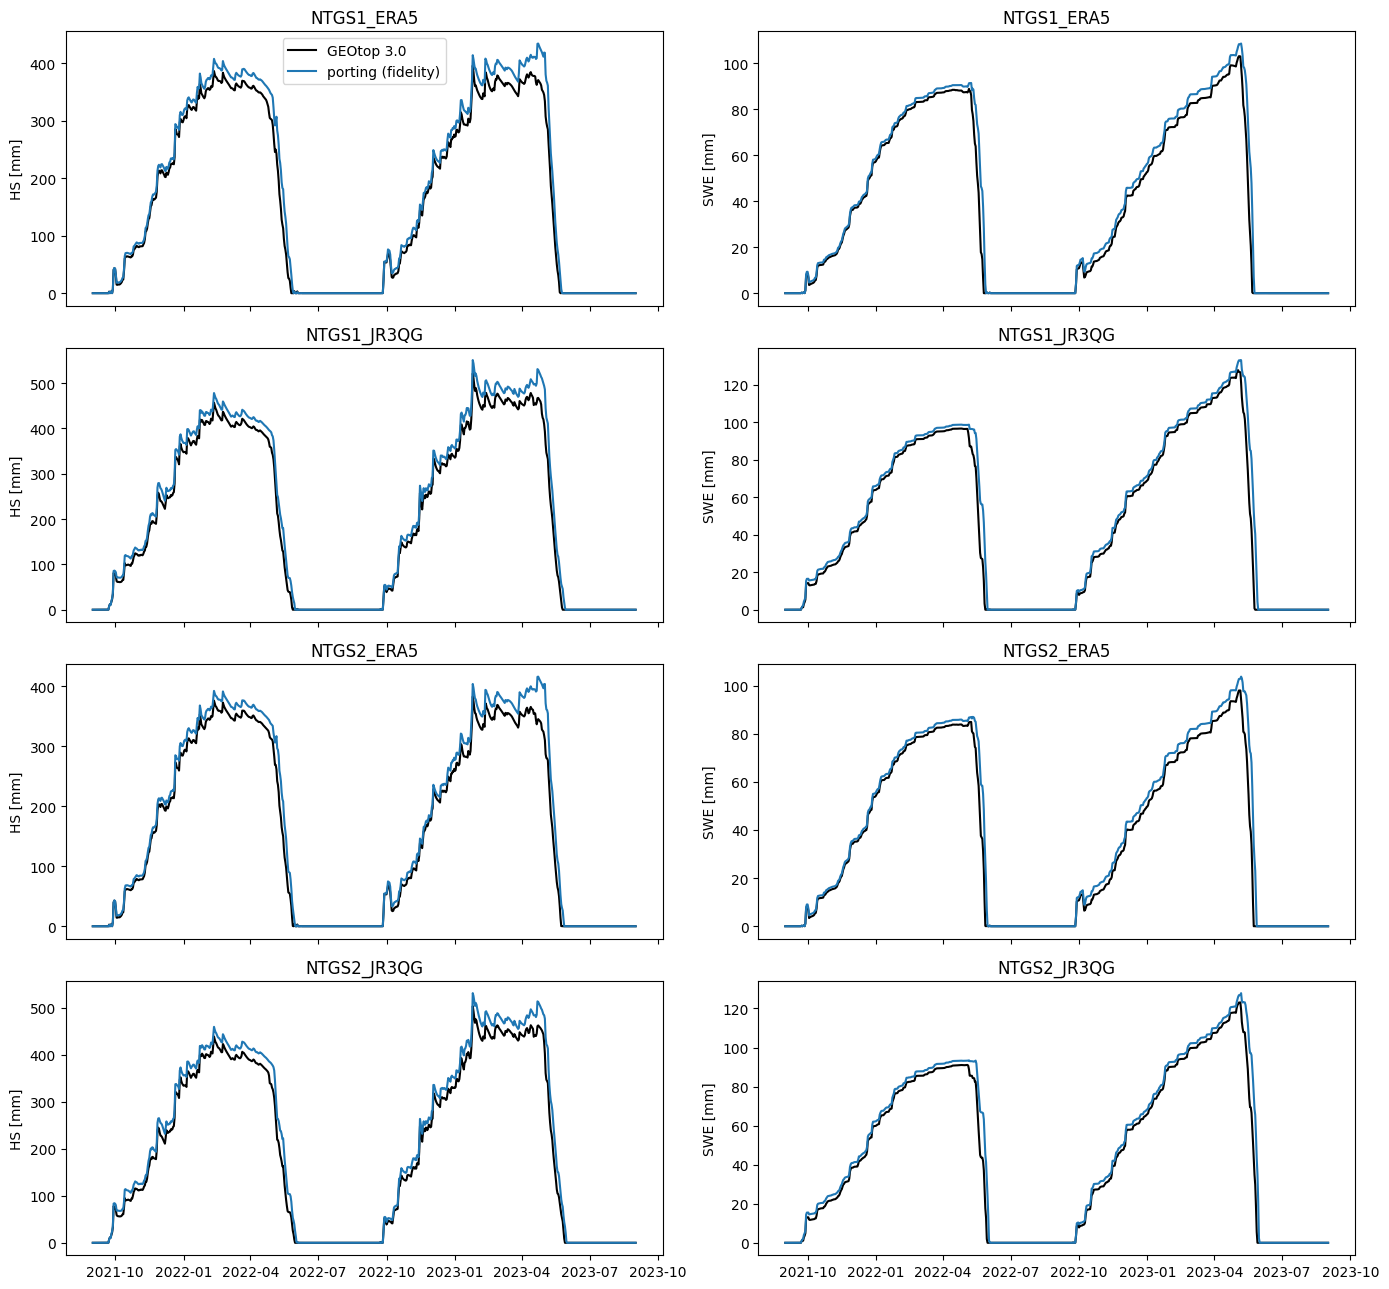

In [3]:
fig, axes = plt.subplots(4, 2, figsize=(14, 13), sharex=True)
for i, c in enumerate(compare.CASES):
    d = data[c].resample("D").mean()
    for j, q in enumerate(("HS", "SWE")):
        ax = axes[i, j]
        ax.plot(d.index, d["gt_" + q], "k", label="GEOtop 3.0")
        ax.plot(d.index, d["wg_" + q], "tab:blue", label="porting (fidelity)")
        ax.set_ylabel(q + " [mm]")
        ax.set_title(c)
axes[0, 0].legend()
fig.tight_layout()

## Soil temperature at 0.1, 0.5, 1, 2 and 4 m (daily means)

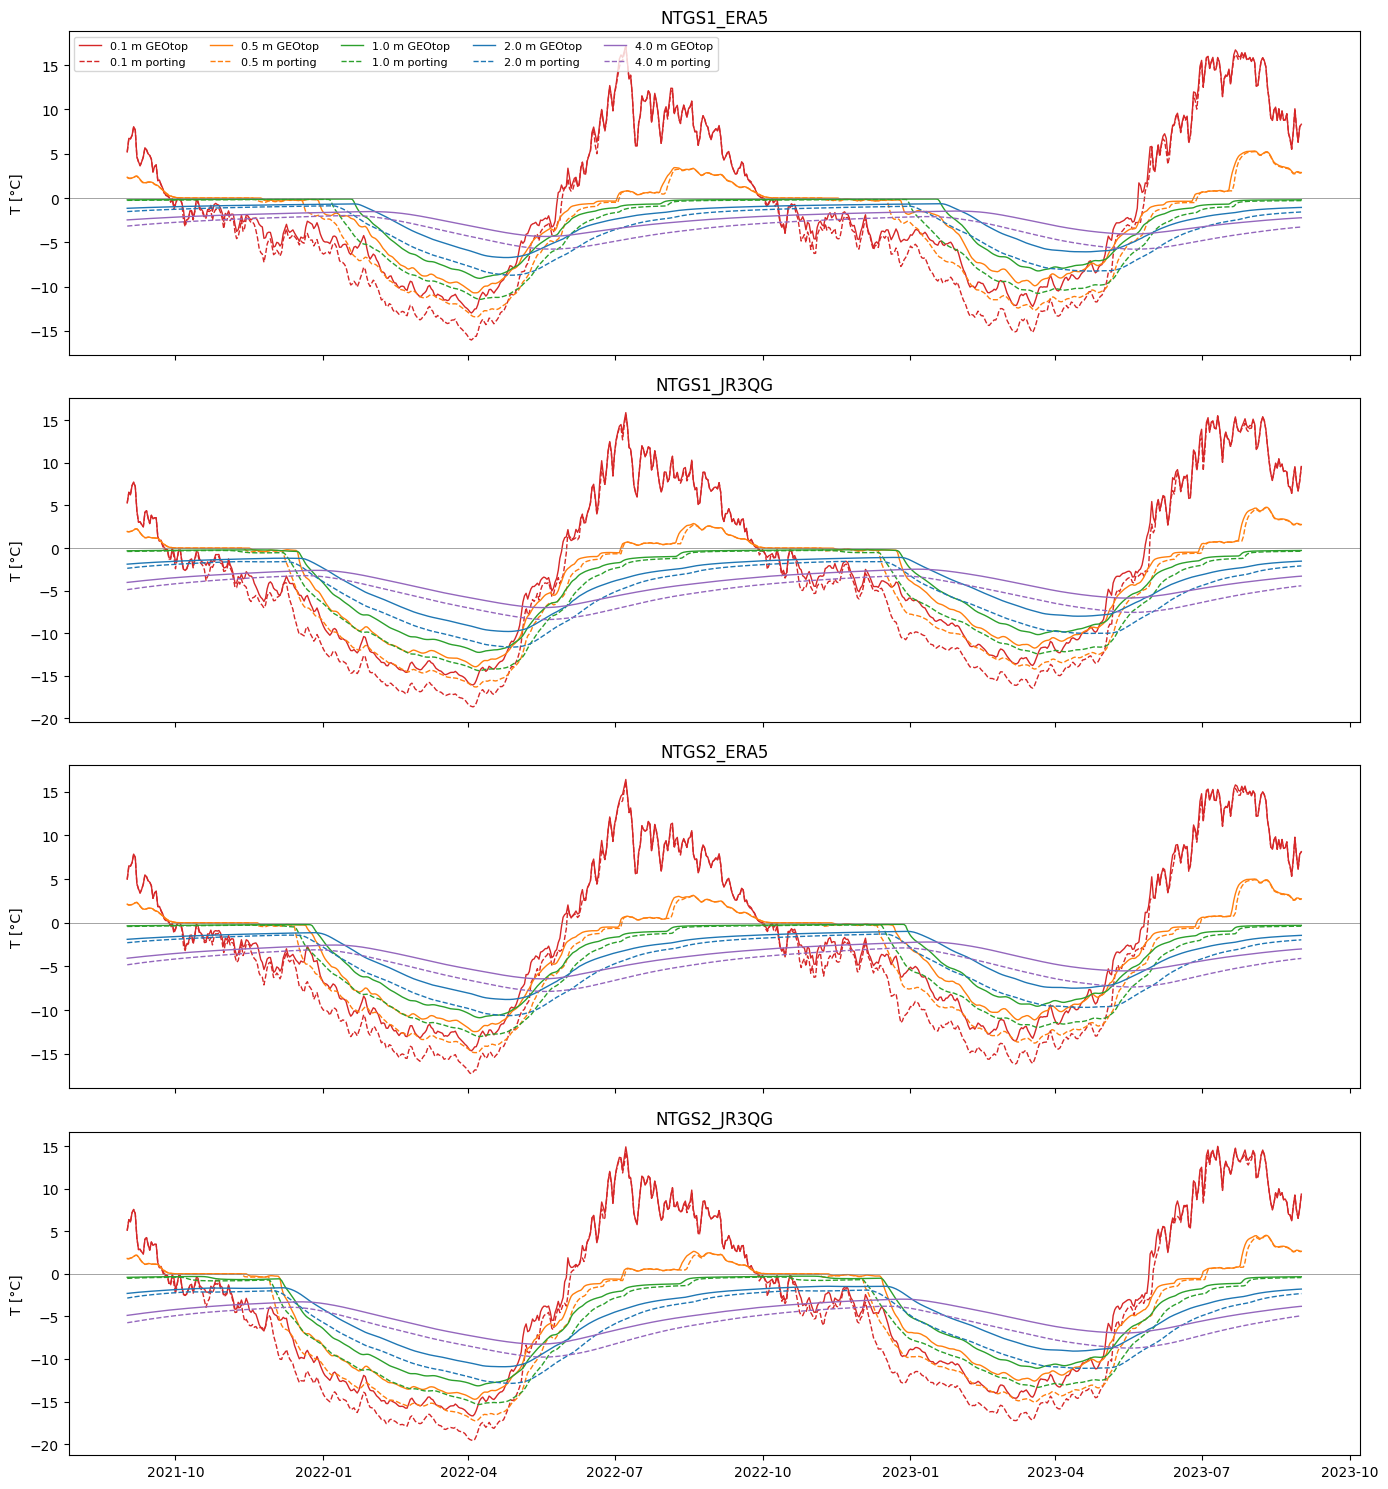

In [4]:
fig, axes = plt.subplots(4, 1, figsize=(14, 15), sharex=True)
colors = dict(zip(compare.DEPTHS_MM, ["tab:red", "tab:orange", "tab:green", "tab:blue", "tab:purple"]))
for ax, c in zip(axes, compare.CASES):
    d = data[c].resample("D").mean()
    for z in compare.DEPTHS_MM:
        ax.plot(d.index, d["gt_T%d" % z], color=colors[z], lw=1, label="%.1f m GEOtop" % (z / 1000))
        ax.plot(d.index, d["wg_T%d" % z], color=colors[z], lw=1, ls="--", label="%.1f m porting" % (z / 1000))
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_ylabel("T [°C]")
    ax.set_title(c)
axes[0].legend(ncol=5, fontsize=8)
fig.tight_layout()

## Monthly bias of soil temperature, porting − GEOtop

The bias builds up in winter, under snow, and it is largest in spring at shallow depths. In summer, when the top is held at GEOtop's `Tsurface`, the shallow layers return to GEOtop's values; the deep layers keep part of the winter deficit.

In [5]:
rows = {}
for c in compare.CASES:
    m = data[c].resample("MS").mean()
    rows[c] = pd.DataFrame({"%.1f m" % (z / 1000): m["wg_T%d" % z] - m["gt_T%d" % z] for z in compare.DEPTHS_MM})
pd.concat(rows, axis=1).round(2)

NTGS1_ERA5                         NTGS1_JR3QG                         NTGS2_ERA5                         NTGS2_JR3QG                        
                          0.1 m 0.5 m 1.0 m 2.0 m 4.0 m       0.1 m 0.5 m 1.0 m 2.0 m 4.0 m      0.1 m 0.5 m 1.0 m 2.0 m 4.0 m       0.1 m 0.5 m 1.0 m 2.0 m 4.0 m
Date12[DDMMYYYYhhmm]                                                                                                                                              
2021-09-01                -0.04 -0.02 -0.05 -0.32 -0.63       -0.06  0.00 -0.07 -0.41 -0.78      -0.04 -0.01 -0.06 -0.34 -0.68       -0.07 -0.00 -0.08 -0.43 -0.79
2021-10-01                -0.32  0.00 -0.04 -0.27 -0.55       -0.39 -0.00 -0.05 -0.33 -0.67      -0.32  0.00 -0.05 -0.27 -0.60       -0.37 -0.00 -0.30 -0.41 -0.68
2021-11-01                -1.04 -0.09 -0.03 -0.22 -0.48       -1.03 -0.09 -0.25 -0.34 -0.59      -0.96 -0.08 -0.04 -0.23 -0.52       -0.84 -0.17 -0.14 -0.36 -0.63
2021-12-01                -1.04 -0.59 -0.03 -0.20 -0.43       -2.57 -2.51 -1.78 -0.89 -0.60      -2.13 -1.92 -1.34 -0.51 -0.48       -3.03 -2.96 -2.19 -1.21 -0.69
2022-01-01                -2.51 -2.50 -2.25 -0.93 -0.44       -2.55 -2.40 -2.15 -1.61 -0.92      -2.54 -2.45 -2.21 -1.69 -0.81       -2.24 -2.10 -1.88 -1.55 -1.04
2022-02-01                -2.98 -2.79 -2.49 -1.82 -0.84       -2.42 -2.22 -1.98 -1.58 -1.10      -2.36 -2.15 -1.92 -1.61 -1.11       -2.15 -1.98 -1.78 -1.52 -1.16
2022-03-01                -2.62 -2.42 -2.19 -1.75 -1.13       -2.54 -2.33 -2.08 -1.65 -1.18      -2.63 -2.37 -2.09 -1.70 -1.22       -2.37 -2.10 -1.85 -1.55 -1.22
2022-04-01                -3.25 -2.87 -2.49 -1.88 -1.24       -2.80 -2.51 -2.23 -1.76 -1.26      -2.58 -2.39 -2.16 -1.81 -1.33       -3.21 -2.75 -2.34 -1.82 -1.31
2022-05-01                -1.92 -2.17 -2.26 -2.05 -1.39       -1.77 -1.92 -2.01 -1.89 -1.38      -1.91 -2.00 -2.04 -1.90 -1.44       -1.95 -2.22 -2.30 -2.10 -1.51
2022-06-01                -0.28 -0.51 -1.07 -1.64 -1.49       -0.28 -0.68 -1.24 -1.72 -1.53      -0.32 -0.65 -1.22 -1.67 -1.56       -0.61 -0.88 -1.41 -1.83 -1.66
2022-07-01                -0.14 -0.12 -0.36 -0.92 -1.28       -0.10 -0.06 -0.39 -1.01 -1.37      -0.13 -0.07 -0.40 -0.94 -1.33       -0.12 -0.08 -0.46 -1.06 -1.45
2022-08-01                -0.09 -0.24 -0.16 -0.60 -1.03       -0.10 -0.27 -0.23 -0.69 -1.13      -0.10 -0.29 -0.20 -0.61 -1.06       -0.13 -0.33 -0.30 -0.70 -1.16
2022-09-01                -0.00 -0.01 -0.07 -0.42 -0.85       -0.03  0.02 -0.08 -0.49 -0.96      -0.00 -0.01 -0.08 -0.41 -0.87       -0.03  0.01 -0.09 -0.48 -0.98
2022-10-01                -0.59 -0.00 -0.06 -0.35 -0.75       -0.62  0.00 -0.06 -0.41 -0.86      -0.57 -0.00 -0.06 -0.34 -0.76       -0.61  0.00 -0.23 -0.42 -0.87
2022-11-01                -1.11 -0.11 -0.05 -0.30 -0.66       -1.05 -0.11 -0.17 -0.37 -0.76      -1.17 -0.11 -0.05 -0.29 -0.67       -0.93 -0.09 -0.27 -0.50 -0.80
2022-12-01                -1.14 -0.74 -0.05 -0.26 -0.60       -2.35 -2.34 -1.66 -0.80 -0.73      -2.48 -2.32 -1.55 -0.54 -0.61       -3.18 -3.31 -2.33 -1.22 -0.83
2023-01-01                -3.27 -3.35 -3.10 -1.41 -0.64       -3.21 -3.09 -2.79 -2.01 -1.08      -3.57 -3.49 -3.16 -2.31 -1.02       -2.65 -2.55 -2.35 -1.98 -1.28
2023-02-01                -3.40 -3.20 -2.89 -2.20 -1.15       -2.63 -2.50 -2.31 -1.94 -1.38      -2.78 -2.69 -2.51 -2.21 -1.50       -2.48 -2.36 -2.18 -1.91 -1.48
2023-03-01                -2.87 -2.77 -2.58 -2.15 -1.46       -2.62 -2.46 -2.27 -1.91 -1.47      -2.84 -2.64 -2.42 -2.11 -1.62       -2.65 -2.44 -2.21 -1.92 -1.54
2023-04-01                -3.21 -2.89 -2.61 -2.15 -1.57       -3.16 -2.77 -2.47 -2.01 -1.53      -3.36 -2.97 -2.65 -2.22 -1.69       -3.09 -2.74 -2.44 -2.06 -1.62
2023-05-01                -1.95 -2.17 -2.37 -2.26 -1.68       -2.10 -2.27 -2.39 -2.24 -1.67      -2.12 -2.37 -2.51 -2.38 -1.84       -2.05 -2.21 -2.35 -2.26 -1.77
2023-06-01                -0.33 -0.38 -0.92 -1.61 -1.68       -0.32 -0.47 -1.05 -1.70 -1.73      -0.29 -0.46 

## Surface temperature with snow (hourly, both models with snow)

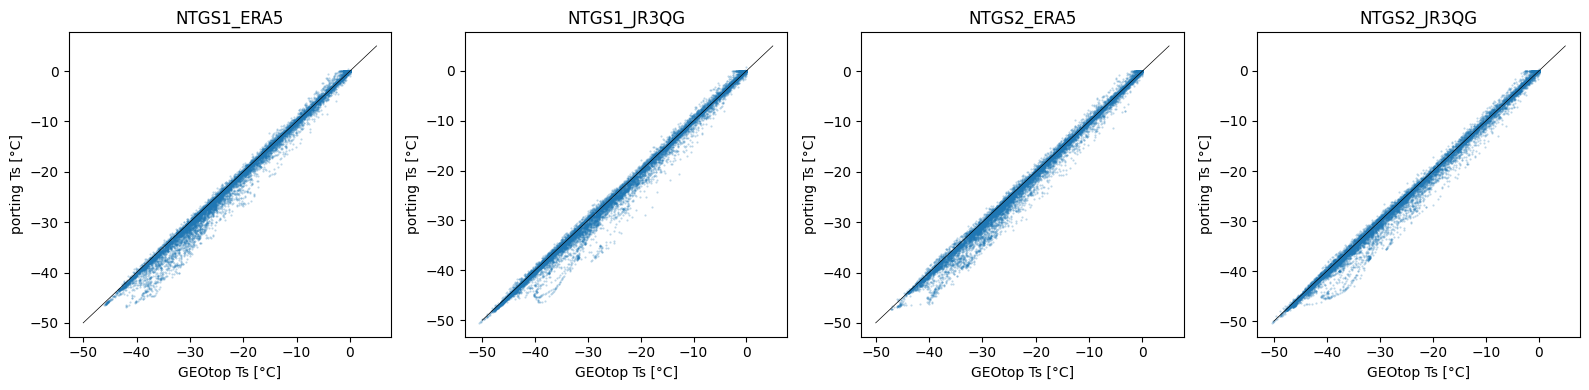

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, compare.CASES):
    d = data[c]
    both = (d.gt_SWE > compare.SNOW_SWE) & (d.wg_SWE > compare.SNOW_SWE)
    ax.plot(d.loc[both, "gt_Ts"], d.loc[both, "wg_Ts"], ".", ms=1, alpha=0.3)
    ax.plot([-50, 5], [-50, 5], "k", lw=0.5)
    ax.set_xlabel("GEOtop Ts [°C]"); ax.set_ylabel("porting Ts [°C]"); ax.set_title(c)
fig.tight_layout()

## Thaw depth (GEOtop's `lowest_thawed_soil_depth` and the same algorithm on the porting's profiles)

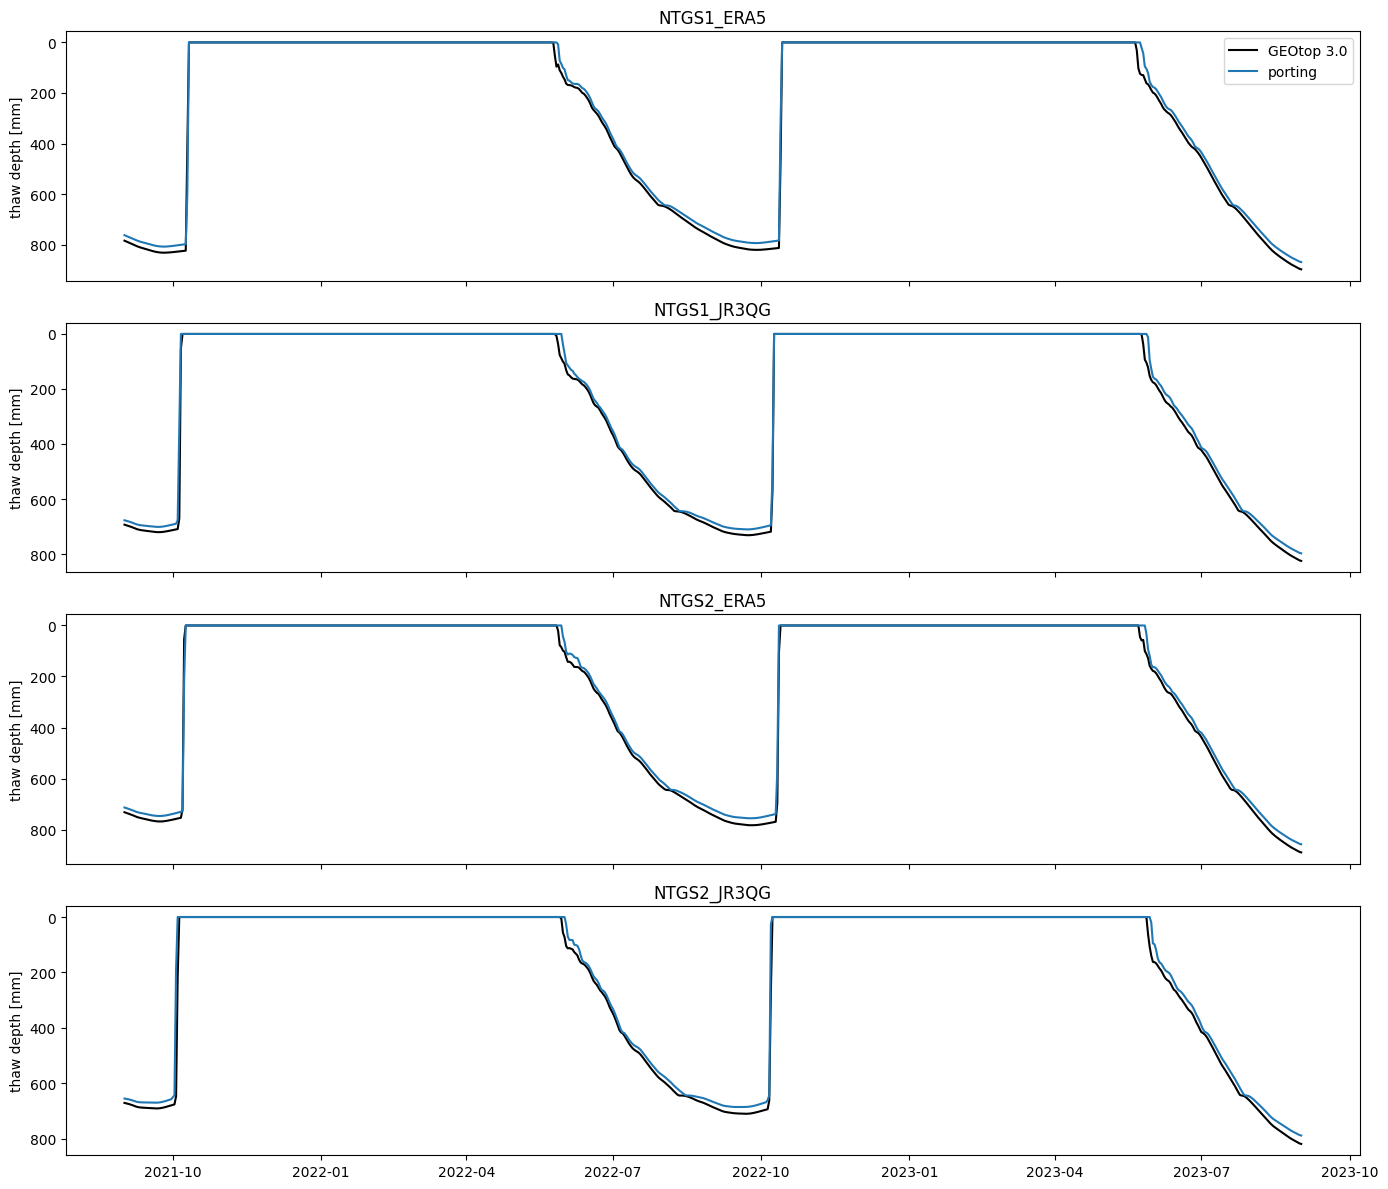

In [7]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
for ax, c in zip(axes, compare.CASES):
    d = data[c].resample("D").mean()
    ax.plot(d.index, d.gt_thaw, "k", label="GEOtop 3.0")
    ax.plot(d.index, d.wg_thaw, "tab:blue", label="porting")
    ax.invert_yaxis(); ax.set_ylabel("thaw depth [mm]"); ax.set_title(c)
axes[0].legend()
fig.tight_layout()

## Attribution of the differences

**Snow**

- SWE follows GEOtop: peaks within 2–6 %, RMSE 6–7 mm.
- Snow-on dates are the same day (−1 to 0 d); snow-off comes 3–5 days late.
- HS is 14–17 mm higher on average. As in Matsch_P2_Ref_007 and DN-14, the pack settles less; this is the open point of SNOW-6.

**Soil 1–1.5 K colder at every depth, and the surface with snow 0.4–0.6 K colder.** The deficit builds up under snow and is largest in March–April (−3 K at 0.1–0.5 m). Below snow the porting receives about half of GEOtop's sensible heat (in December 2020 at NTGS1 ERA5: −3 against −8 W m⁻²). The cause was traced to GEOtop, not to the porting's turbulence:

1. Fed with **GEOtop's own** state of each hour (start surface temperature, Ta, RH, wind, P), the porting's Monin–Obukhov gives a sensible heat close to GEOtop's in the stable hours where GEOtop's Obukhov length is positive.
2. In **12–31 % of the snow hours** the air is stable at the start of the step, yet GEOtop reports a **negative** Obukhov length. In those hours GEOtop's H is 3–4 times the porting's: about −11 to −14 against −3.4 W m⁻² (table below, from GEOtop's `point0001.txt`).
3. The only path in GEOtop 3.0 that can give an unstable L from a stable start is the recomputation of the turbulence inside the Newton loop:
   - it runs when an iterate of the surface temperature falls below −50 °C (`flagTmin`, `energy.balance.cc:58-59, 1835-1840`);
   - after 10 iterations the resistances are recomputed **without stable correction**, at the current iterate (`EnergyFluxes_no_rec_turbulence`, `energy.balance.cc:2618-2621`);
   - if that iterate is warmer than the air, L is negative.

   This emergency path is documented as not ported (`MoninObukhov` javadoc). In this Arctic case it is active in a large part of the winter, so it is a **porting difference** that matters, not a numerical detail. Confirming it requires an instrumented GEOtop run, which is an open issue.

| case | stable start, GEOtop L > 0: hours, H GEOtop / porting MO | stable start, GEOtop L ≤ 0: hours, H GEOtop / porting MO |
|---|---|---|
| NTGS1 ERA5 | 54 %, −8.6 / −6.6 | 31 %, −11.5 / −3.4 |
| NTGS1 JRA-3Q | 81 %, −7.1 / −6.0 | 15 %, −14.0 / −3.3 |
| NTGS2 ERA5 | 59 %, −8.4 / −6.5 | 28 %, −11.1 / −3.7 |
| NTGS2 JRA-3Q | 84 %, −7.0 / −6.1 | 12 %, −13.9 / −3.4 |

Other contributions:

- **Snow–soil interface conductance.** The porting uses the harmonic mean; GEOtop applies Cosenza to the thickness-weighted means of the contents, which is the open fidelity item of SNOW-3. GEOtop's rule conducts more, so it would make GEOtop colder, not warmer: it does not explain the sign.
- **Thin-snow roughness and emissivity**, not ported. They matter only below 10 mm of snow (`ThresSnowSoilRough` = `SoilRoughness` = 10 mm by default): a few days in autumn.

**Thaw depth.** The porting is 20–30 mm shallower at the summer maximum, and the daily RMSE is 18–26 mm. In summer the top is conditioned on GEOtop's `Tsurface`, so what remains is the winter deficit carried into the soil.

**Numerics.**

- About 60–70 s per case: 3 years hourly, 20 soil cells, 26 280 steps.
- Three cases have no rejected step.
- In NTGS1 JRA-3Q, one hour of 5 October 2021 is rejected 6 times. The cause is a saturated peat cell at 0 °C (0.26–0.42 m) that misses the per-cell bound of 10⁻³ J m⁻² by 0.006–0.03 J m⁻² even at 225 s. With the case's `onNonConvergence = Flag`, two sub-steps are accepted and marked degraded. With `Stop`, the component's default, the run stops there and saves the state.